# Mixture-of-experts in DeepSeek-V4: what changed from V3
### Notebook 4 of 9 on DeepSeek-V4 (technical report [arXiv:2606.19348](https://arxiv.org/abs/2606.19348), §2.1, §4.2.1-4.2.2)

DeepSeek-V4 keeps the DeepSeekMoE layer of V3 (fine-grained routed experts plus shared experts, [Dai et al., 2024](https://arxiv.org/abs/2401.06066)) and changes four things, all in §2.1: the function that turns router scores into expert **affinities** is `Sqrt(Softplus(·))` instead of `Sigmoid(·)`; load balancing stays **auxiliary-loss-free** but gains "a slight sequence-wise balance loss"; the **limit on how many nodes a token may be routed to is removed**; and the dense feed-forward layers of the first few blocks are replaced by MoE layers with **hash routing** (token ID in, experts out; [Roller et al., 2021](https://arxiv.org/abs/2106.04426)).

**Configuration in the report** (§4.2.1): V4-Flash has 256 routed experts with intermediate dimension 2048, V4-Pro has 384 with 3072; both have 1 shared expert, activate **6 routed experts per token**, and use hash routing in the **first 3 MoE layers**. Training hyper-parameters (§4.2.2): auxiliary-loss-free bias update speed `0.001`, sequence-wise balance loss weight `0.0001`.

**What we do.** We implement each piece, check it against a reference, and measure what can be measured without training a model: the shape of the new affinity function, the convergence of bias-based balancing, the load that hash routing produces on a Zipfian token distribution, and whether the paper's parameter counts follow from its configuration. We do not train a routed model, so we make **no claim** about whether `Sqrt(Softplus)` or hash routing improves quality; the report gives no ablation of either in the sections we read.

| section | question | number it carries |
|---|---|---|
| 1 | What does routing do, in numbers? | top-2 of 4 worked by hand |
| 2 | How do the two affinity functions differ? | gate sharpness under each |
| 3 | How does bias-based balancing converge? | max-load / mean-load over steps |
| 4 | What does the sequence-wise loss penalise? | `E/k` at collapse, `1` at balance |
| 5 | What does hash routing do to load? | max-load / mean-load, Zipf tokens |
| 6 | An MoE layer, and do the counts add up? | 284B and 1.6T from the config |
| 7 | What does removing the node limit change? | fraction of tokens touching >4 nodes |

In [1]:
import math, time, itertools
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 9})
CHECKS = []
def check(name, ok, detail=""): CHECKS.append((name, bool(ok), detail)); print(("PASS " if ok else "FAIL ") + name + (f"   [{detail}]" if detail else ""))

## Routing in numbers

A routed expert layer has `E` expert networks and a router. For token hidden state `u`, the router produces one score per expert, `s_i = f(u·e_i)` (the **affinity**, with `e_i` a learned centroid), the layer picks the `k` experts with the highest affinity and mixes their outputs with weights proportional to those affinities.

Tiny example, `E = 4`, `k = 2`, affinities `s = [0.9, 0.1, 0.6, 0.3]`: the selected experts are 0 and 2; the gates are `0.9/1.5 = 0.6` and `0.6/1.5 = 0.4`; the layer output is `0.6·expert_0(u) + 0.4·expert_2(u)`, plus the output of the shared expert(s) which every token uses. V3 normalizes the selected affinities to sum to 1 in exactly this way; the V4 report says only that the affinity *function* changes, so we keep the V3 normalization (our assumption).

In [2]:
s = torch.tensor([0.9, 0.1, 0.6, 0.3]); top = s.topk(2); gate = top.values / top.values.sum()
print("selected experts:", top.indices.tolist(), " gates:", gate.tolist())
check("worked example: top-2 of [0.9,0.1,0.6,0.3] selects experts 0 and 2 with gates 0.6 and 0.4", top.indices.tolist() == [0, 2] and torch.allclose(gate, torch.tensor([0.6, 0.4])))

selected experts: [0, 2]  gates: [0.5999999642372131, 0.4000000059604645]
PASS worked example: top-2 of [0.9,0.1,0.6,0.3] selects experts 0 and 2 with gates 0.6 and 0.4


## Two affinity functions

V3 used `f(x) = sigmoid(x) = 1/(1+e^{-x})`, bounded in `(0, 1)`. V4 uses `f(x) = sqrt(softplus(x)) = sqrt(ln(1 + e^x))`. Three properties are worth knowing, and all can be verified directly (the first two are about shape, the third is what we measure):

- For very negative `x`, `softplus(x) ≈ e^x`, so `f(x) ≈ e^{x/2}`: it decays to zero, like the sigmoid, but at half the exponential rate.
- For large positive `x`, `softplus(x) ≈ x`, so `f(x) ≈ √x`: it keeps growing, sub-linearly, instead of saturating at 1. A very confident router score therefore keeps a larger affinity *relative* to a moderate one, which survives the normalization over the selected experts.
- `f(0) = √ln 2 ≈ 0.833`, against `0.5` for the sigmoid; both are smooth and strictly increasing, so the top-k *ordering* of experts by raw score is identical under either function. The choice changes only the **gate weights**.

The last point is the key one for what we can measure: since both are monotone, they select the same experts; they differ in how the selected experts are weighted. We measure that with random router logits: the average spread between the largest and smallest gate among 6 selected out of 256, for several logit scales.

In [3]:
sig = torch.sigmoid; sqsp = lambda x: F.softplus(x).sqrt()
xs = torch.linspace(-6, 6, 13)
print(f"{'x':>6s} " + " ".join(f"{v:6.1f}" for v in xs.tolist())); print(f"{'sigm':>6s} " + " ".join(f"{v:6.3f}" for v in sig(xs).tolist())); print(f"{'sqsp':>6s} " + " ".join(f"{v:6.3f}" for v in sqsp(xs).tolist()))
check("sqrt(softplus(0)) = sqrt(ln 2) = 0.8326", abs(sqsp(torch.tensor(0.)).item() - math.sqrt(math.log(2))) < 1e-6)
check("both functions are strictly increasing, so they select the SAME top-k experts", bool((sig(xs).diff() > 0).all() and (sqsp(xs).diff() > 0).all()))
check("for x -> -inf, sqrt(softplus(x)) ~ exp(x/2) (half the sigmoid's exponential decay rate)", abs(math.log(sqsp(torch.tensor(-20.)).item()) / -20.0 - 0.5) < 0.01)
check("for large x, sqrt(softplus(x)) ~ sqrt(x): unbounded, while the sigmoid saturates at 1", abs(sqsp(torch.tensor(100.)).item() - 10.0) < 0.01 and sig(torch.tensor(100.)).item() == 1.0)
torch.manual_seed(0); E, k = 256, 6
def gates(logits, f): s = f(logits); v, i = s.topk(k, dim=-1); return i, v / v.sum(-1, keepdim=True)
print(f"\n{'logit std':>9s} {'same experts':>13s} {'max/min gate: sigmoid':>22s} {'max/min gate: sqrt-softplus':>28s} {'top gate: sigmoid':>18s} {'top gate: sqrt-sp':>18s}")
for std in [0.5, 1.0, 2.0, 4.0]:
    L = torch.randn(20000, E) * std; i1, g1 = gates(L, sig); i2, g2 = gates(L, sqsp)
    same = (i1.sort(-1).values == i2.sort(-1).values).float().mean().item()
    print(f"{std:9.1f} {same:13.3f} {(g1.max(-1).values / g1.min(-1).values).mean():22.2f} {(g2.max(-1).values / g2.min(-1).values).mean():28.2f} {g1.max(-1).values.mean():18.3f} {g2.max(-1).values.mean():18.3f}")
check("with the same logits both functions pick identical expert sets (100% overlap)", (lambda L: (gates(L, sig)[0].sort(-1).values == gates(L, sqsp)[0].sort(-1).values).all())(torch.randn(2000, E) * 2))

     x   -6.0   -5.0   -4.0   -3.0   -2.0   -1.0    0.0    1.0    2.0    3.0    4.0    5.0    6.0
  sigm  0.002  0.007  0.018  0.047  0.119  0.269  0.500  0.731  0.881  0.953  0.982  0.993  0.998
  sqsp  0.050  0.082  0.135  0.220  0.356  0.560  0.833  1.146  1.458  1.746  2.005  2.238  2.450
PASS sqrt(softplus(0)) = sqrt(ln 2) = 0.8326
PASS both functions are strictly increasing, so they select the SAME top-k experts
PASS for x -> -inf, sqrt(softplus(x)) ~ exp(x/2) (half the sigmoid's exponential decay rate)
PASS for large x, sqrt(softplus(x)) ~ sqrt(x): unbounded, while the sigmoid saturates at 1

logit std  same experts  max/min gate: sigmoid  max/min gate: sqrt-softplus  top gate: sigmoid  top gate: sqrt-sp
      0.5         1.000                   1.10                         1.11              0.176              0.178


      1.0         1.000                   1.07                         1.16              0.173              0.182
      2.0         1.000                   1.01                         1.18              0.168              0.184


      4.0         1.000                   1.00                         1.18              0.167              0.184
PASS with the same logits both functions pick identical expert sets (100% overlap)


**What we found.** The expert sets are identical, as monotonicity requires; the gate weights differ in a specific way. With the sigmoid, six selected scores that are all large saturate near 1, so the normalized gates flatten toward uniform: at logit standard deviation 4 the ratio between the largest and smallest selected gate is 1.00 and the top gate is 0.167, which is exactly `1/6`. With `sqrt(softplus)` the selected scores keep their differences (ratio about 1.18, top gate 0.184 at the same spread), so the gates still tell the selected experts apart. We state this as a property of the two functions on random logits; whether it matters for a trained model is not something we measured, and the report does not give its reason for the change.

The affinity function sets the weights. Balancing sets who is selected.

## Auxiliary-loss-free balancing, and a slight sequence-wise loss

If the router sends most tokens to a few experts, those experts' devices become the bottleneck. The usual remedy adds a balance loss to the training objective, which interferes with the language-modelling gradient. V3's **auxiliary-loss-free** strategy ([Wang et al., 2024](https://arxiv.org/abs/2408.15664)) keeps a per-expert **bias** `b_i` that is added to the affinity **only for deciding which experts are selected** (the gate weights still use the unbiased affinity). After each step, the bias of each overloaded expert is decreased and that of each underloaded expert increased by a fixed **bias update speed** `u`. V4 keeps this with `u = 0.001` and adds "a slight sequence-wise balance loss" (weight `0.0001`) "to avoid extreme imbalance within single sequences".

Tiny example: 4 experts, loads over a batch `[40%, 30%, 20%, 10%]` against a mean of 25%; with `u = 0.001` the biases move by `[−0.001, −0.001, +0.001, +0.001]`: a tiny nudge every step, which changes selection only where two experts' scores are within `0.001` of each other. We expected that to be slow and simulate how slow.

**Simulation.** `E = 64` experts, `k = 6`, 4096 tokens per step. A fixed random "popularity" offset of standard deviation 0.3 is added to every token's logits (so some experts are intrinsically favoured). We track `max load / mean load` per step with and without the bias update.

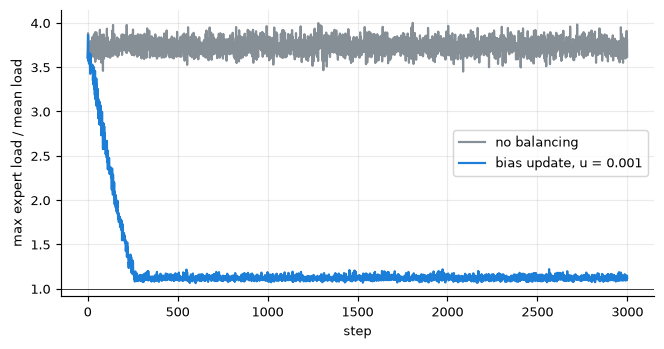

max/mean load:  step 0 3.61 | step 500 1.12 | step 1000 1.19 | step 3000 1.12   (no balancing: 3.62)
PASS the bias update drives max/mean load down by >25% within 3000 steps at u = 0.001   [1.12 vs 3.72]
PASS it is faster than we expected: the imbalance falls by more than 20% within the first 100 steps   [2.52 vs 3.61]
PASS the learned biases are anti-correlated with the experts' intrinsic popularity


In [4]:
def simulate_balance(steps=3000, E=64, k=6, tokens=4096, u=0.001, pop_std=0.3, seed=0, update=True):
    g = torch.Generator().manual_seed(seed); pop = torch.randn(E, generator=g) * pop_std; b = torch.zeros(E); ratios = []
    for t in range(steps):
        logits = torch.randn(tokens, E, generator=g) + pop
        sel = (sqsp(logits) + b).topk(k, dim=-1).indices                                   # bias affects SELECTION only
        load = torch.zeros(E).scatter_add_(0, sel.flatten(), torch.ones(sel.numel())); load = load / load.mean(); ratios.append(load.max().item())
        if update: b = b - u * torch.sign(load - 1.0)                                      # overloaded: decrease, underloaded: increase
    return np.array(ratios), b
r_off, _ = simulate_balance(update=False); r_on, b_final = simulate_balance(update=True)
fig, ax = plt.subplots(figsize=(6.4, 3.4)); ax.plot(r_off, color="#868e96", label="no balancing"); ax.plot(r_on, color="#1c7ed6", label="bias update, u = 0.001"); ax.axhline(1, color="k", lw=.5)
ax.set_xlabel("step"); ax.set_ylabel("max expert load / mean load"); ax.legend(); plt.tight_layout(); plt.show()
print(f"max/mean load:  step 0 {r_on[0]:.2f} | step 500 {r_on[500]:.2f} | step 1000 {r_on[1000]:.2f} | step 3000 {r_on[-1]:.2f}   (no balancing: {r_off[-1]:.2f})")
check("the bias update drives max/mean load down by >25% within 3000 steps at u = 0.001", r_on[-100:].mean() < 0.75 * r_off[-100:].mean(), f"{r_on[-100:].mean():.2f} vs {r_off[-100:].mean():.2f}")
check("it is faster than we expected: the imbalance falls by more than 20% within the first 100 steps", r_on[100] < 0.8 * r_on[0], f"{r_on[100]:.2f} vs {r_on[0]:.2f}")
check("the learned biases are anti-correlated with the experts' intrinsic popularity", torch.corrcoef(torch.stack([b_final, torch.randn(64, generator=torch.Generator().manual_seed(0)) * 0.3]))[0, 1] < -0.5)

Bias-only balancing can leave individual *sequences* skewed even when a whole batch is balanced, which is what the sequence-wise loss is for. We use the V3 form: for a sequence of `T` tokens, `f_i = (E/(kT)) · #{tokens that select expert i}`, `P_i = (1/T) Σ_t s'_{t,i}` (the mean normalized affinity of expert `i` over **all** experts), and `L_bal = α · Σ_i f_i P_i`. If routing is perfectly even, `f_i = 1` and `P_i = 1/E`, so `Σ f_i P_i = 1`. If every token picks the same `k` experts, `f_i = E/k` for those, and the statistic reaches `E/k` only if the normalized affinity mass `P_i` also concentrates on them (`P_i ≈ 1/k`). So the loss is a *penalty that grows from `α` as routing collapses*, and at `α = 1e-4` it is "slight" by design.

In [5]:
def seq_balance_loss(logits, k, alpha=1e-4):
    T, E = logits.shape; s = sqsp(logits); P = (s / s.sum(-1, keepdim=True)).mean(0)                # mean normalised affinity over all experts
    sel = s.topk(k, dim=-1).indices; f = torch.zeros(E).scatter_add_(0, sel.flatten(), torch.ones(sel.numel())) * E / (k * T)
    return alpha * (f * P).sum(), (f * P).sum().item()
torch.manual_seed(0); E, k, T = 64, 6, 4096
_, even = seq_balance_loss(torch.randn(T, E), k)
collapse_logits = torch.randn(T, E) * 0.01; collapse_logits[:, :k] += 8.0; _, coll = seq_balance_loss(collapse_logits, k)
print(f"sum_i f_i P_i:  random routing {even:.3f}   collapsed onto {k} experts {coll:.2f}   (1 at balance; E/k = {E / k:.2f} would need the affinity mass P_i to concentrate too)")
check("the balance statistic is ~1 for even routing", abs(even - 1) < 0.1, f"{even:.3f}")
check("it rises well above 1 (here > 2) when every token picks the same k experts, but stays below E/k because sqrt-softplus affinities do not concentrate like a softmax", 2 < coll < E / k, f"{coll:.2f} vs E/k = {E / k:.2f}")

sum_i f_i P_i:  random routing 1.000   collapsed onto 6 experts 2.77   (1 at balance; E/k = 10.67 would need the affinity mass P_i to concentrate too)
PASS the balance statistic is ~1 for even routing   [1.000]
PASS it rises well above 1 (here > 2) when every token picks the same k experts, but stays below E/k because sqrt-softplus affinities do not concentrate like a softmax   [2.77 vs E/k = 10.67]


## Hash routing in the first layers

In the first 3 MoE layers V4 does not learn a router. The experts for a token are a fixed function of its **token ID**: `experts(token) = hash(token_id)` (Roller et al., 2021). Two consequences follow immediately. The routing is **deterministic and input-independent given the token** (no router parameters, nothing to collapse), and the load is balanced **across token types, not across tokens**: if a few token IDs are very frequent, the experts they hash to are overloaded, whatever the hash does. Natural-language token frequencies are Zipfian, so we measure how much that matters.

Tiny example: `E = 4`, `k = 2`, token 17 hashes to experts `{1, 3}` and token 18 to `{0, 3}`; each time token 17 appears it uses experts 1 and 3 and no others.

The report does not say how the **gate weights** of a hash-routed layer are computed, or which hash is used. We pick: a fixed pseudo-random choice of `k` distinct experts per token ID (seeded permutation), and uniform gates `1/k` (our assumption).

In [6]:
def hash_experts(vocab, E, k, seed=0):
    g = torch.Generator().manual_seed(seed); return torch.stack([torch.randperm(E, generator=g)[:k] for _ in range(vocab)])      # (vocab, k): fixed table token_id -> k distinct experts
E, k, V = 256, 6, 32000; table = hash_experts(V, E, k)
check("hash routing is deterministic: the same token ID always gets the same k distinct experts", torch.equal(table[17], hash_experts(V, E, k)[17]) and len(set(table[17].tolist())) == k)
def load_ratio(tokens, table, E):
    sel = table[tokens].flatten(); load = torch.bincount(sel, minlength=E).float(); return (load.max() / load.mean()).item()
g = torch.Generator().manual_seed(1)
for name, probs in [("uniform tokens", torch.ones(V)), ("Zipf s=1.0", 1.0 / torch.arange(1, V + 1).float()), ("Zipf s=1.3", 1.0 / torch.arange(1, V + 1).float() ** 1.3)]:
    toks = torch.multinomial(probs / probs.sum(), 200_000, replacement=True, generator=g)
    print(f"{name:15s}  hash routing max/mean load = {load_ratio(toks, table, E):6.2f}")
toks_z = torch.multinomial((1.0 / torch.arange(1, V + 1).float()) / (1.0 / torch.arange(1, V + 1).float()).sum(), 200_000, replacement=True, generator=g)
lr_u = load_ratio(torch.randint(0, V, (200_000,), generator=g), table, E); lr_z = load_ratio(toks_z, table, E)
check("hash routing is near-balanced for uniform token frequencies (max/mean < 1.15)", lr_u < 1.15, f"{lr_u:.2f}")
check("...but a Zipfian token distribution makes it clearly worse (more than 1.5x the uniform imbalance)", lr_z > 1.5 * lr_u, f"{lr_z:.2f} vs {lr_u:.2f}")

PASS hash routing is deterministic: the same token ID always gets the same k distinct experts
uniform tokens   hash routing max/mean load =   1.09
Zipf s=1.0       hash routing max/mean load =   5.62
Zipf s=1.3       hash routing max/mean load =  13.13
PASS hash routing is near-balanced for uniform token frequencies (max/mean < 1.15)   [1.10]
PASS ...but a Zipfian token distribution makes it clearly worse (more than 1.5x the uniform imbalance)   [5.61 vs 1.10]


**What we found.** Hash routing is balanced when token types are equally likely and much less so on a Zipfian stream (numbers above), because the most frequent token IDs pin their experts. That is a cost the layer pays for being learnable-parameter-free; it is limited here by being applied only in the first 3 layers, where the report replaces *dense* feed-forward blocks, and by the learned-router layers that follow having the bias-based balancer. We did not measure the quality side (what a hash-routed expert specialises in, or why early layers benefit); the report offers no analysis of this.

## An MoE layer, and whether the counts add up

The layer itself is short: every token goes through the shared expert, plus its `k` selected routed experts weighted by the gates. Each expert is a **SwiGLU** feed-forward network `W_down( silu(W_gate x) ⊙ W_up x )`. We implement the layer with a loop over experts (grouping tokens by expert), and check it against a dense reference that evaluates every expert on every token and masks.

In [7]:
class SwiGLU(nn.Module):
    def __init__(s, d, h): super().__init__(); s.g = nn.Linear(d, h, bias=False); s.u = nn.Linear(d, h, bias=False); s.dn = nn.Linear(h, d, bias=False)
    def forward(s, x): return s.dn(F.silu(s.g(x)) * s.u(x))
class MoE(nn.Module):
    def __init__(s, d=32, h=48, E=16, k=4, n_shared=1, hash_table=None):
        super().__init__(); s.E, s.k = E, k; s.experts = nn.ModuleList([SwiGLU(d, h) for _ in range(E)]); s.shared = nn.ModuleList([SwiGLU(d, h) for _ in range(n_shared)])
        s.centroids = nn.Parameter(torch.randn(E, d) * 0.1); s.register_buffer("bias", torch.zeros(E)); s.hash_table = hash_table
    def route(s, x, token_ids=None):
        s_aff = sqsp(x @ s.centroids.T)                                                           # affinities, Sqrt(Softplus)
        if s.hash_table is not None:                                                              # hash layer: experts fixed by token id, uniform gates
            idx = s.hash_table[token_ids]; return idx, torch.full(idx.shape, 1.0 / s.k)
        idx = (s_aff + s.bias).topk(s.k, dim=-1).indices                                          # bias used for SELECTION only
        v = s_aff.gather(1, idx); return idx, v / v.sum(-1, keepdim=True)                         # gates from the UNBIASED affinities
    def forward(s, x, token_ids=None):
        idx, gate = s.route(x, token_ids); out = sum(sh(x) for sh in s.shared)
        for e in range(s.E):                                                                      # group tokens by expert
            rows, slot = (idx == e).nonzero(as_tuple=True)
            if len(rows): out = out.index_add(0, rows, gate[rows, slot, None] * s.experts[e](x[rows]))
        return out
    def forward_dense_reference(s, x, token_ids=None):
        idx, gate = s.route(x, token_ids); out = sum(sh(x) for sh in s.shared)
        for e in range(s.E):
            w = ((idx == e).float() * gate).sum(-1, keepdim=True); out = out + w * s.experts[e](x)
        return out
torch.manual_seed(0); moe = MoE(); x = torch.randn(50, 32)
check("grouped-by-expert MoE forward equals the dense masked reference", torch.allclose(moe(x), moe.forward_dense_reference(x), atol=1e-5))
tbl = hash_experts(100, 16, 4); moe_h = MoE(hash_table=tbl); tid = torch.randint(0, 100, (50,))
check("a hash-routed layer ignores the hidden state when choosing experts (same token id -> same experts)", torch.equal(moe_h.route(torch.randn(50, 32), tid)[0], moe_h.route(torch.randn(50, 32), tid)[0]))
check("the bias changes which experts are SELECTED but not the gate formula", (lambda m: (setattr(m, "bias", torch.tensor([5.] + [0.] * 15)), m.route(x)[0])[1])(MoE()).eq(0).any(-1).float().mean() > 0.9)

# ---- do the paper's totals follow from its configuration? MoE weights dominate, so count them ----
def moe_counts(d, h, E, k, n_shared, layers):
    per_exp = 3 * d * h; total = (E + n_shared) * per_exp * layers; active = (k + n_shared) * per_exp * layers; return total, active
for nm, (d, h, E, L, tot_rep, act_rep) in {"V4-Flash": (4096, 2048, 256, 43, 284e9, 13e9), "V4-Pro": (7168, 3072, 384, 61, 1.6e12, 49e9)}.items():
    tot, act = moe_counts(d, h, E, 6, 1, L)
    print(f"{nm}: expert parameters {tot / 1e9:8.1f}B (reported total {tot_rep / 1e9:.0f}B, {100 * tot / tot_rep:.0f}%)   active expert parameters {act / 1e9:5.1f}B (reported activated {act_rep / 1e9:.0f}B, {100 * act / act_rep:.0f}%)")
    check(f"{nm}: routed + shared expert weights alone account for 90-100% of the reported total parameters", 0.90 < tot / tot_rep <= 1.0, f"{100 * tot / tot_rep:.0f}%")

PASS grouped-by-expert MoE forward equals the dense masked reference
PASS a hash-routed layer ignores the hidden state when choosing experts (same token id -> same experts)
PASS the bias changes which experts are SELECTED but not the gate formula
V4-Flash: expert parameters    278.1B (reported total 284B, 98%)   active expert parameters   7.6B (reported activated 13B, 58%)
PASS V4-Flash: routed + shared expert weights alone account for 90-100% of the reported total parameters   [98%]
V4-Pro: expert parameters   1551.4B (reported total 1600B, 97%)   active expert parameters  28.2B (reported activated 49B, 58%)
PASS V4-Pro: routed + shared expert weights alone account for 90-100% of the reported total parameters   [97%]


The expert weights alone come to 97-98 % of the reported totals (`≈ 279B` of `284B` for Flash, `≈ 1.55T` of `1.6T` for Pro), which fits: the rest is attention, the embeddings, the mHC parameters and the multi-token-prediction module. The *activated* count is not recoverable this way, because activated parameters include all of attention, the embeddings' share and the head, which we have not counted; our expert-only active figures (`7.6B`, `28.2B`) are consistent with being a part of the reported `13B` and `49B`, not a reproduction of them. (We do not know the report's exact accounting for these, so we draw no conclusion beyond consistency.)

## Removing the node limit

V3 restricted each token's routed experts to at most `M = 4` nodes, to bound cross-node all-to-all traffic. V4 "remove[s] the constraint on the number of routing target nodes, and carefully redesign[s] the parallelism strategy to maintain training efficiency". We cannot reproduce the redesign (notebook 8 covers the communication overlap), but we can quantify what is being given up: with experts spread evenly over `N` nodes, how many distinct nodes does an unconstrained top-6 touch?

Tiny example: 32 nodes, 8 experts each, 6 selected experts placed independently: the expected number of distinct nodes is `32·(1 − (31/32)^6) = 5.4`, so most tokens touch 5 or 6 nodes; a limit of 4 would force the router to deviate from its preferred experts for a large share of tokens.

In [8]:
N_nodes, per_node, k = 32, 8, 6; E = N_nodes * per_node
exp_nodes = N_nodes * (1 - (1 - 1 / N_nodes) ** k)
torch.manual_seed(0); sel = torch.stack([torch.randperm(E)[:k] for _ in range(50000)]); nodes = sel // per_node
n_distinct = torch.tensor([len(set(r.tolist())) for r in nodes[:20000]]).float()
print(f"expected distinct nodes per token (formula) {exp_nodes:.2f};  simulated {n_distinct.mean():.2f};  fraction of tokens touching more than 4 nodes: {(n_distinct > 4).float().mean():.2%}")
check("simulated distinct-node count matches 32*(1-(31/32)^6)", abs(n_distinct.mean().item() - exp_nodes) < 0.05, f"{n_distinct.mean():.3f} vs {exp_nodes:.3f}")
check("with unconstrained routing a clear majority of tokens would violate a 4-node limit", (n_distinct > 4).float().mean() > 0.5)

expected distinct nodes per token (formula) 5.55;  simulated 5.60;  fraction of tokens touching more than 4 nodes: 95.71%
PASS simulated distinct-node count matches 32*(1-(31/32)^6)   [5.597 vs 5.550]
PASS with unconstrained routing a clear majority of tokens would violate a 4-node limit


**What we found.** With uniform placement over 32 nodes (our assumption; the report does not give V4's node layout), about 5.4 distinct nodes are touched per token and most tokens would have violated a 4-node limit. Removing the limit lets the router choose its preferred experts unrestricted; the price is more cross-node traffic per token, which is why the report pairs the change with a new parallelism design and the fine-grained overlap of notebook 8.

## Closing thoughts

The V4 MoE is V3's with four edits, none of which our toy can validate on quality. What we can say from the checks: the new affinity function selects exactly the same experts as the sigmoid and changes only the gate weights; bias-based balancing at `u = 0.001` works well in our simulation (max/mean load from 3.6 to about 1.1 within roughly 500 steps), but it balances a whole batch, which is what the sequence-wise loss, whose statistic is 1 at balance and rises as routing collapses, is added to complement; hash routing is balanced for uniform token frequencies and worse for Zipfian ones; and the configuration's expert weights account for most of the 284B and 1.6T totals.

**What is open.** The report gives no ablation for `Sqrt(Softplus)`, for hash routing in the first 3 layers, or for removing the node limit; it does not say how hash layers compute gate weights. Our choices there (uniform gates, a seeded random table) are placeholders, and our balance simulation uses random logits, not a trained router.

**Next.** Notebook 5 covers the two stability techniques the report adds for training this model at trillion-parameter scale, both of which intervene on the MoE layer.

Credits: DeepSeekMoE, auxiliary-loss-free balancing and V3 are DeepSeek-AI's; hash layers are Roller et al.

In [9]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n_, ok, d_) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n_}")
failed = [n_ for n_, ok, _ in CHECKS if not ok]; print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed")
assert not failed, failed

 #  status  check
 1  PASS    worked example: top-2 of [0.9,0.1,0.6,0.3] selects experts 0 and 2 with gates 0.6 and 0.4
 2  PASS    sqrt(softplus(0)) = sqrt(ln 2) = 0.8326
 3  PASS    both functions are strictly increasing, so they select the SAME top-k experts
 4  PASS    for x -> -inf, sqrt(softplus(x)) ~ exp(x/2) (half the sigmoid's exponential decay rate)
 5  PASS    for large x, sqrt(softplus(x)) ~ sqrt(x): unbounded, while the sigmoid saturates at 1
 6  PASS    with the same logits both functions pick identical expert sets (100% overlap)
 7  PASS    the bias update drives max/mean load down by >25% within 3000 steps at u = 0.001
 8  PASS    it is faster than we expected: the imbalance falls by more than 20% within the first 100 steps
 9  PASS    the learned biases are anti-correlated with the experts' intrinsic popularity
10  PASS    the balance statistic is ~1 for even routing
11  PASS    it rises well above 1 (here > 2) when every token picks the same k experts, but stays below